In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [2]:
# Parameters
t = 1
s = 0
r = 0.9
p = 0.2
epsilon = 0.1
d = 0.7
alpha = 0.3
bound = 1 / (1 - d)

In [11]:
algo = Algorithm(
        e=epsilon, lambda_val=0, alpha=alpha, delta=d,
        init_mode='fixed', tolerance=1e-10000, 
        M=int(50), case_id=0, verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()  
exp = np.random.randint(0, 50)
q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]  

In [12]:
q1

,Q1,Q2,Q3,Q4
0,1.649315,0.323191,0.766339,0.889139
1,1.967479,0.481554,1.141846,0.834818
2,2.123380,0.559152,1.325844,0.808200
3,2.199771,0.597175,1.416003,0.795157
4,2.237203,0.615807,1.460181,0.788766
5,2.255544,0.624936,1.481828,0.785635
6,2.264532,0.629409,1.492435,0.784100
7,2.268936,0.631601,1.497632,0.783349
8,2.271093,0.632675,1.500179,0.782980
9,2.272151,0.633202,1.501427,0.782800


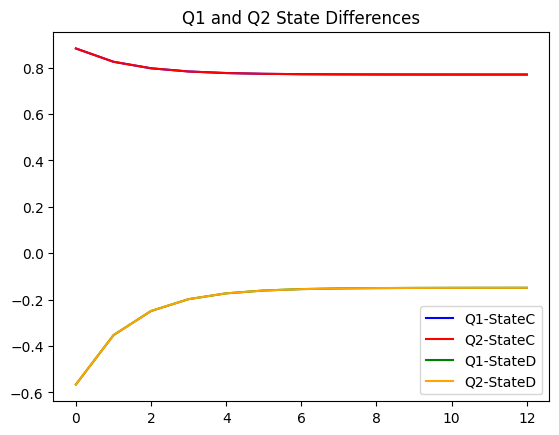

In [13]:
internal_debug = True
if internal_debug:
    q1['StateC'] = q1['Q1'] - q1['Q3']
    q1['StateD'] = q1['Q2'] - q1['Q4']
    q2['StateC'] = q2['Q1'] - q2['Q3']
    q2['StateD'] = q2['Q2'] - q2['Q4']
    x = q1['StateC'].values
    y = q2['StateC'].values
    z = q1['StateD'].values
    w = q2['StateD'].values
    pd.Series(x).plot(title='Q1-StateC', color='blue')
    pd.Series(y).plot(title='Q2-StateC', color='red')
    pd.Series(z).plot(title='Q1-StateD', color='green')
    pd.Series(w).plot(title='Q2-StateD', color='orange')
    plt.title('Q1 and Q2 State Differences')
    plt.legend(['Q1-StateC', 'Q2-StateC', 'Q1-StateD', 'Q2-StateD'])


In [14]:
#q1.join(q2, rsuffix='_q2', lsuffix='_q1')


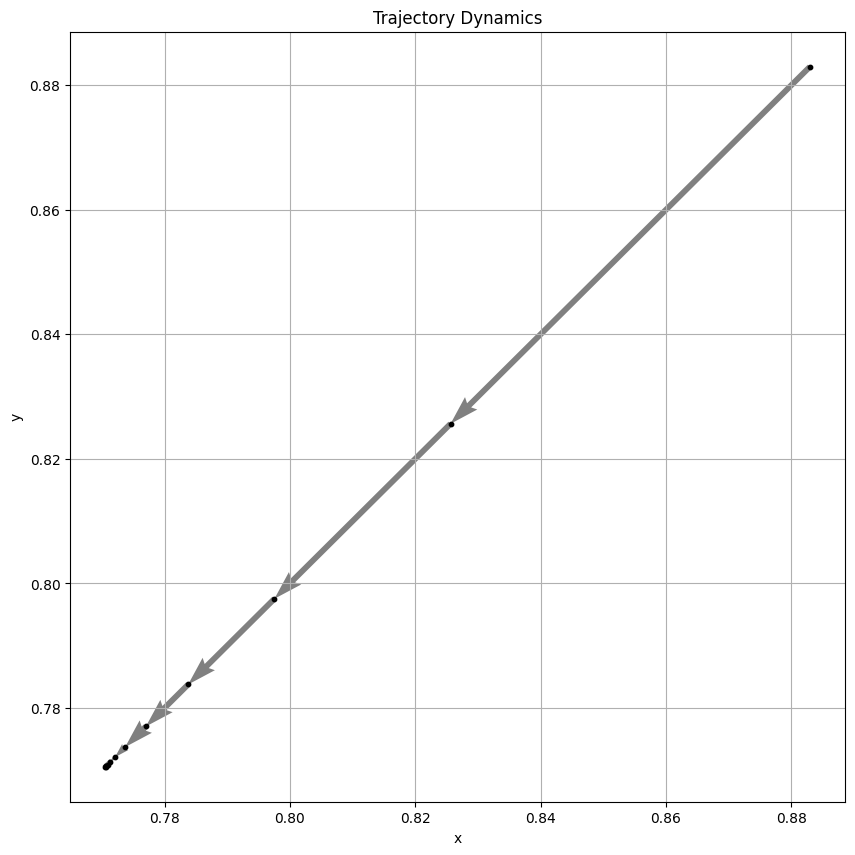

In [15]:
trajectory_dynamics_plot(x, y)

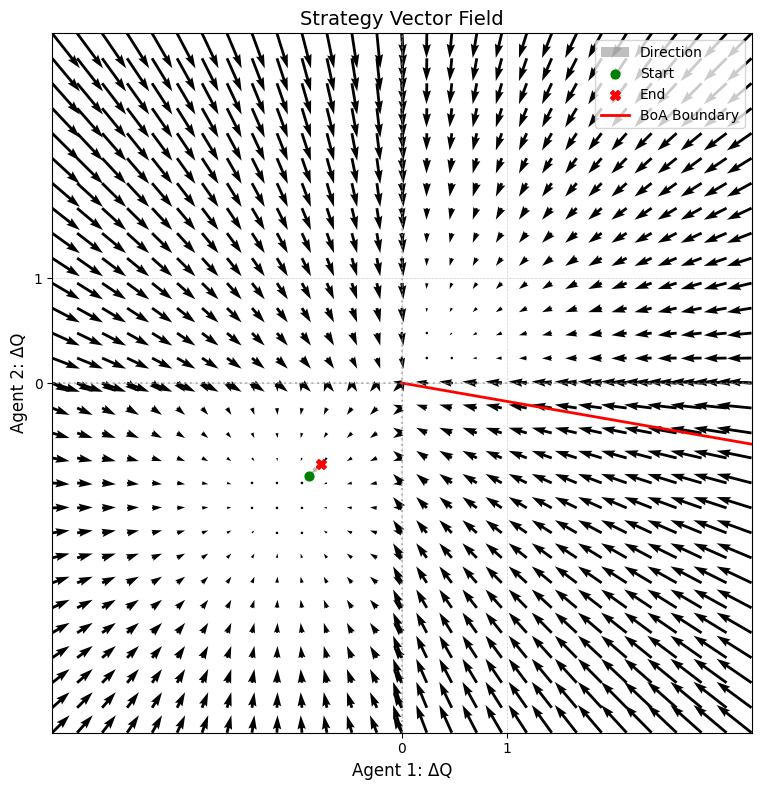

In [16]:
plotter = VectorFieldPlotter(q1 = q1, q2 = q2,
    t=t, r=r, p=p, s=s, alpha=alpha,
    bound=bound,
    epsilon=epsilon, delta=d,
    q_func_gt=QvaluesGTvsGT,
    q_func_ad=QvaluesADvs00, 
    x_state = 'StateC',
    y_state = 'StateC', method = "quiver",cmap=cm.viridis,
    show_trajectory=True,
    show_basin=True, 

)
plotter.plot()

In [17]:
plotter = VectorFieldPlotter_single(
    t=1, r=0.9, p=0.2, s=0,
    epsilon=0.1, delta=0.7,
    q_func_gt=QvaluesGTvsGT,
    q_func_ad=QvaluesADvs00,
    alpha=0.3,
    show_trajectory=False,
    show_basin=True
)

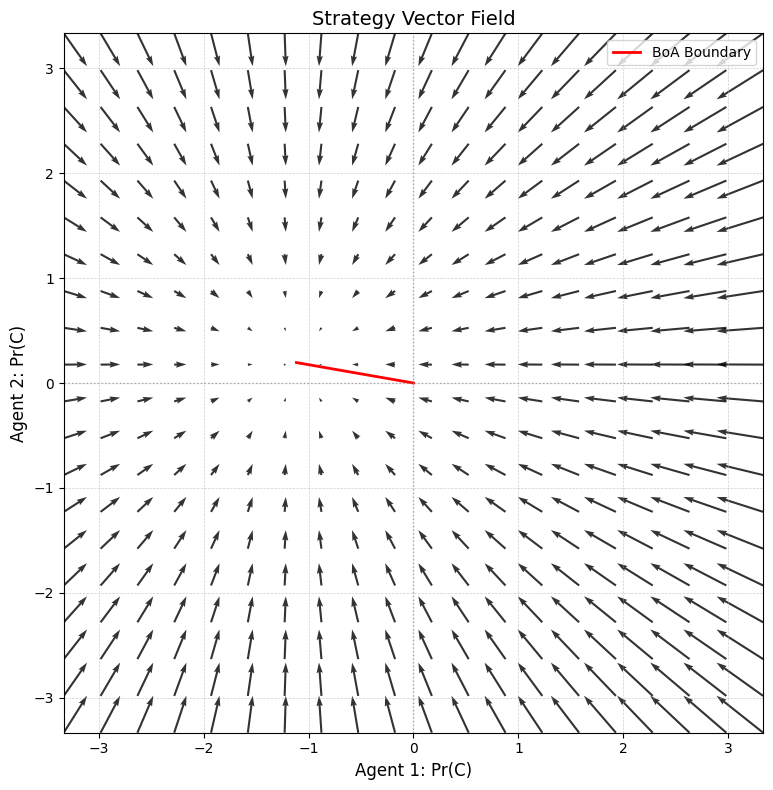

In [18]:
plotter.plot()